<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-01/lab-003a-trained-networks-pytorch.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 003a
<hr/>

# Lab 003a — Working with trained networks: saving, inspecting, modifying and fine-tuning (PyTorch)

Training a network is rarely the last step. A trained network is a set of arrays (the parameters) together with a description of the computation (the architecture), and most of the daily work consists of doing things *with* it: storing it, reloading it, looking at what it has learned, cutting it into pieces, adding layers, and re-using it for a new problem. This lab is the toolbox for these operations.

We train one small **convolutional neural network (CNN)** on the handwritten digits 0–4 of MNIST and then use it in every section:

1. **Train once and save.** Train the CNN, write its parameters to disk, load them into a fresh model, and check that the predictions are identical.
2. **Inspect.** Layers, parameter shapes and counts, access to single weights, trainable vs frozen parameters.
3. **Look inside.** First-layer kernels as images, and the feature maps of one digit after each convolutional layer (forward hooks).
4. **Model surgery.** Cut the network into a feature extractor, attach a new head, insert a layer, replace a layer.
5. **Freezing and transfer learning.** A new task, the digits 5–9, with few labelled images: (a) random initialisation, (b) the trained body frozen and only a new head trained, (c) fine-tuning of all parameters after (b).
6. **Cheat sheet.** Every operation of this lab in PyTorch and in JAX/Flax side by side.

The twin notebook **Lab 003b** does exactly the same in JAX with Flax NNX and optax: same data, same architecture, same sections, same printed quantities. The two can be read side by side.

Abbreviations used below: CNN (convolutional neural network), ReLU (rectified linear unit, $\mathrm{ReLU}(z)=\max(0,z)$), Adam (adaptive moment estimation, the optimiser), CPU / GPU (central / graphics processing unit).

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The notebook runs on the **CPU** (the first code cell hides all GPUs); the model and the data sets are small enough to finish in a few minutes.
> 2. `numpy`, `matplotlib` and `torch` are pre-installed in Colab.
> 3. The data are read from `data/MNIST_raw/` (the four `*-ubyte.gz` files). If they are missing, the notebook downloads them.
> 4. Run the cells *in order*: later cells use variables defined earlier. If the state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""     # hide all GPUs: everything runs on the CPU (set before importing torch)
os.environ["JAX_PLATFORMS"] = "cpu"         # the same choice for JAX, in case it is imported in this session

import copy, gzip, time, urllib.request
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})
def noframe(ax):                            # image panels: no ticks, no frame
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)

torch.set_num_threads(min(4, os.cpu_count()))   # small convolutions: more threads add more synchronisation than speed
t_start = time.time()
print("PyTorch", torch.__version__, "| CPU threads used:", torch.get_num_threads(), "| GPU visible:", torch.cuda.is_available())

PyTorch 2.9.0+cpu | CPU threads used: 4 | GPU visible: False


<hr/>
## 1. Train once and save

### 1.1 The data: two tasks from one data set

MNIST contains $28\times28$ grayscale images of handwritten digits, $60\,000$ for training and $10\,000$ for testing. We split it into two tasks:

* **source task**: digits 0–4, all training images of these digits. The CNN is trained on it in this section;
* **target task**: digits 5–9, used in Section 5. Their labels are shifted, $5\to0,\dots,9\to4$, so both tasks have 5 classes.

The files are in the raw IDX format: a short big-endian header (a magic number, then the sizes), followed by one byte per pixel; we read them with `gzip` and `numpy`. Pixels are scaled to $[0,1]$.

**Layout of image tensors.** PyTorch convolutions expect `(N, C, H, W)`: batch size, channels, height, width. Our images are therefore stored as `(N, 1, 28, 28)`. (JAX/Flax uses `(N, H, W, C)`, see Lab 003b.)

In [2]:
MNIST_DIR = "data/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
               "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]                                                  # 3 for images, 1 for labels
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")        # big-endian int32 sizes
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").astype(np.float32) / 255.0   # (60000, 28, 28)
ytr_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int64)
Xte_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").astype(np.float32) / 255.0   # (10000, 28, 28)
yte_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int64)

def task(X, y, digits):
    # images of the given digits as (N, 1, 28, 28) float32 and labels shifted to 0 .. len(digits)-1
    keep = np.isin(y, digits)
    return torch.tensor(X[keep][:, None, :, :]), torch.tensor(y[keep] - digits[0])

Xs_tr, ys_tr = task(Xtr_all, ytr_all, [0, 1, 2, 3, 4])     # source task: digits 0-4
Xs_te, ys_te = task(Xte_all, yte_all, [0, 1, 2, 3, 4])
Xt_pool, yt_pool = task(Xtr_all, ytr_all, [5, 6, 7, 8, 9]) # target task: labelled images are drawn from this pool in Section 5
Xt_te, yt_te = task(Xte_all, yte_all, [5, 6, 7, 8, 9])

assert Xs_tr.shape[1:] == (1, 28, 28) and Xs_tr.dtype == torch.float32
print("source task (digits 0-4): train", tuple(Xs_tr.shape), "| test", tuple(Xs_te.shape))
print("target task (digits 5-9): pool ", tuple(Xt_pool.shape), "| test", tuple(Xt_te.shape))
print("pixel range:", Xs_tr.min().item(), "to", Xs_tr.max().item())

source task (digits 0-4): train (30596, 1, 28, 28) | test (5139, 1, 28, 28)
target task (digits 5-9): pool  (29404, 1, 28, 28) | test (4861, 1, 28, 28)
pixel range: 0.0 to 1.0


### 1.2 The architecture: a convolutional body and a dense head

The network (conv–pool–conv–pool–dense–output) is split into two named parts, because Sections 4 and 5 treat them separately:

* the **body** (the convolutional feature extractor) maps an image to a feature vector of $32\cdot7\cdot7=1568$ numbers,
$$
(N,1,28,28)\xrightarrow{\text{conv }5\times5,\ 16}(N,16,28,28)\xrightarrow{\text{ReLU, max-pool }2}(N,16,14,14)\xrightarrow{\text{conv }3\times3,\ 32}(N,32,14,14)\xrightarrow{\text{ReLU, max-pool }2}(N,32,7,7)\xrightarrow{\text{flatten}}(N,1568);
$$
* the **head** (the classifier) is a dense layer with ReLU and an output layer, $(N,1568)\xrightarrow{\text{fc, ReLU}}(N,64)\xrightarrow{\text{out}}(N,5)$, giving 5 logits (unnormalised log-probabilities of the classes).

`padding=2` for the $5\times5$ kernel and `padding=1` for the $3\times3$ kernel keep the height and width unchanged, so only the pooling layers halve them. Both parts are `nn.Sequential` containers built from an `OrderedDict`: every layer gets a readable name (`conv1`, `relu1`, …), which appears in the parameter names (`body.conv1.weight`) and lets us address single layers later.

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=5):
        super().__init__()
        self.body = nn.Sequential(OrderedDict([
            ("conv1",   nn.Conv2d(1, 16, kernel_size=5, padding=2)),    # (N,1,28,28)  -> (N,16,28,28)
            ("relu1",   nn.ReLU()),
            ("pool1",   nn.MaxPool2d(2)),                               # -> (N,16,14,14)
            ("conv2",   nn.Conv2d(16, 32, kernel_size=3, padding=1)),   # -> (N,32,14,14)
            ("relu2",   nn.ReLU()),
            ("pool2",   nn.MaxPool2d(2)),                               # -> (N,32,7,7)
            ("flatten", nn.Flatten()),                                  # -> (N,1568), order (channel, row, column)
        ]))
        self.head = nn.Sequential(OrderedDict([
            ("fc",      nn.Linear(32 * 7 * 7, 64)),                     # (N,1568) -> (N,64)
            ("relu3",   nn.ReLU()),
            ("out",     nn.Linear(64, n_classes)),                      # (N,64) -> (N,n_classes) logits
        ]))

    def forward(self, x):
        return self.head(self.body(x))

torch.manual_seed(0)
model = SmallCNN()
out = model(Xs_tr[:8])
assert out.shape == (8, 5) and model.body(Xs_tr[:8]).shape == (8, 1568)
print("logits of 8 images:", tuple(out.shape), "| feature vectors:", tuple(model.body(Xs_tr[:8]).shape))

logits of 8 images: (8, 5) | feature vectors: (8, 1568)


### 1.3 Training on the source task

Standard supervised training: cross-entropy loss on the logits, Adam with learning rate $10^{-3}$, minibatches of 128 images, one epoch (one pass over the $30\,596$ training images, 239 steps). The minibatch order comes from a NumPy generator with a fixed seed, so Lab 003b sees exactly the same sequence of minibatches.

Two helpers are used for the rest of the notebook: `train_steps` performs a given number of gradient steps on randomly drawn minibatches, and `accuracy` evaluates in chunks of 2000 images under `torch.inference_mode()` (no computational graph is recorded). `model.train()` / `model.eval()` switch layers such as dropout or batch normalisation between their training and evaluation behaviour; our network has none, but calling them is a habit worth having.

In [4]:
def accuracy(model, X, y, chunk=2000):
    # fraction of correctly classified images
    model.eval()
    with torch.inference_mode():
        pred = torch.cat([model(X[i:i + chunk]).argmax(dim=1) for i in range(0, len(X), chunk)])
    return (pred == y).float().mean().item()

def train_epochs(model, X, y, epochs, batch_size, lr, seed):
    # plain training loop: one random permutation of the data per epoch
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    rng = np.random.default_rng(seed)
    n_batches = len(X) // batch_size                  # the last incomplete batch is dropped
    for epoch in range(epochs):
        model.train()
        perm = rng.permutation(len(X))[: n_batches * batch_size].reshape(n_batches, batch_size)
        losses = []
        for idx in perm:
            idx = torch.from_numpy(idx)
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: mean training loss {np.mean(losses):.4f} | test accuracy (digits 0-4) {accuracy(model, Xs_te, ys_te):.4f}")

t0 = time.time()
torch.manual_seed(0)
model = SmallCNN()
train_epochs(model, Xs_tr, ys_tr, epochs=1, batch_size=128, lr=1e-3, seed=0)
acc_source = accuracy(model, Xs_te, ys_te)
print(f"training time: {time.time() - t0:.1f} s | final test accuracy on digits 0-4: {acc_source:.4f}")

epoch 1: mean training loss 0.1997 | test accuracy (digits 0-4) 0.9887


training time: 10.0 s | final test accuracy on digits 0-4: 0.9887


### 1.4 Saving and loading the parameters

**What is saved.** `model.state_dict()` is an ordered dictionary `{parameter name: tensor}`, e.g. `"body.conv1.weight" → tensor of shape (16, 1, 5, 5)`. It contains the numbers only, not the code of the class. `torch.save` writes it to a file (a zip archive of the tensors).

**Loading** requires the architecture: we create a *fresh* `SmallCNN` (random parameters) and copy the stored numbers into it with `load_state_dict`. The names and shapes must match; otherwise PyTorch raises an error listing the missing or unexpected keys. `torch.load(..., weights_only=True)` reads tensors only and refuses arbitrary Python objects, which makes loading a file from an unknown source safe.

(The alternative `torch.save(model)` pickles the whole object including a reference to its class; such a file breaks as soon as the class definition is moved or renamed, and is therefore not recommended.)

The check: before loading, the fresh model gives different logits; after loading, the logits on the whole test set are **bit-for-bit identical** (`torch.equal`, not just close).

In [5]:
os.makedirs("checkpoints", exist_ok=True)
CKPT = "checkpoints/cnn_digits04_torch.pt"
torch.save(model.state_dict(), CKPT)
print(f"saved {len(model.state_dict())} tensors to {CKPT} ({os.path.getsize(CKPT) / 1e3:.0f} kB)")

torch.manual_seed(123)                                  # a different seed: different random parameters
fresh = SmallCNN()
with torch.inference_mode():
    print("fresh model, logits equal to the trained model before loading:", torch.equal(fresh(Xs_te), model(Xs_te)))

state = torch.load(CKPT, weights_only=True)             # dict {name: tensor}
fresh.load_state_dict(state)                            # copies the numbers into the existing parameters
fresh.eval(); model.eval()
with torch.inference_mode():
    same_logits = torch.equal(fresh(Xs_te), model(Xs_te))
assert same_logits
print("after load_state_dict, logits on all", len(Xs_te), "test images identical:", same_logits)
print(f"test accuracy of the reloaded model: {accuracy(fresh, Xs_te, ys_te):.4f}")

saved 8 tensors to checkpoints/cnn_digits04_torch.pt (427 kB)


fresh model, logits equal to the trained model before loading: False


after load_state_dict, logits on all 5139 test images identical: True


test accuracy of the reloaded model: 0.9887


<hr/>
## 2. Inspect

### 2.1 Layers, parameter shapes and counts

`print(model)` shows the module tree. `model.named_parameters()` yields every trainable array with its full name. PyTorch shapes follow the convention **(output, input, …)**:

* `Conv2d` weight: `(out_channels, in_channels, kernel_height, kernel_width)`, bias: `(out_channels,)`;
* `Linear` weight: `(out_features, in_features)`, so that $y = x W^{T} + b$, bias: `(out_features,)`.

The number of parameters of a layer is the number of weights plus the number of biases, e.g. for `conv1`: $16\cdot1\cdot5\cdot5+16=416$.

In [6]:
print(model)
print()
print(f"{'parameter':22s} {'shape':>18s} {'count':>8s}")
for name, p in model.named_parameters():
    print(f"{name:22s} {str(tuple(p.shape)):>18s} {p.numel():8d}")
n_total = sum(p.numel() for p in model.parameters())
print(f"{'total':22s} {'':>18s} {n_total:8d}")

# per layer: weights + biases of each module that owns parameters
print()
for lname, layer in model.named_modules():
    own = list(layer.parameters(recurse=False))
    if own:
        print(f"layer {lname:12s} ({type(layer).__name__:6s}): {sum(p.numel() for p in own):6d} parameters")
assert n_total == (16*1*5*5 + 16) + (32*16*3*3 + 32) + (1568*64 + 64) + (64*5 + 5)

SmallCNN(
  (body): Sequential(
    (conv1): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (relu1): ReLU()
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu2): ReLU()
    (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (head): Sequential(
    (fc): Linear(in_features=1568, out_features=64, bias=True)
    (relu3): ReLU()
    (out): Linear(in_features=64, out_features=5, bias=True)
  )
)

parameter                           shape    count
body.conv1.weight           (16, 1, 5, 5)      400
body.conv1.bias                     (16,)       16
body.conv2.weight          (32, 16, 3, 3)     4608
body.conv2.bias                     (32,)       32
head.fc.weight                 (64, 1568)   100352
head.fc.bias                        (64,)       64
head.out.weig

Almost all parameters ($100\,416$ of $105\,797$) sit in the dense layer `head.fc`, which connects all $1568$ outputs of the convolutional part to 64 units; the two convolutional layers together have only $5\,056$, because a kernel is shared over all positions of the image.

### 2.2 Access to a single layer

A layer is reached by attribute access along its name: `model.body.conv1`. Its parameters are `.weight` and `.bias`, tensors with `requires_grad=True`. To use them as plain numbers, call `.detach()` (a tensor without a gradient history, sharing the memory) and `.numpy()`; to modify them by hand, do it inside `torch.no_grad()` so that the change is not recorded by automatic differentiation.

In [7]:
conv1 = model.body.conv1                              # the same object as model.body[0]
assert conv1 is model.body[0]
W1 = conv1.weight.detach().numpy()                    # (16, 1, 5, 5)
b1 = conv1.bias.detach().numpy()                      # (16,)
print("conv1 weight:", W1.shape, "| bias:", b1.shape, "| requires_grad:", conv1.weight.requires_grad)
print("kernel 0 (5 x 5):\n", np.round(W1[0, 0], 3))
print("output layer weight:", tuple(model.head.out.weight.shape), "(out_features, in_features) | bias:", np.round(model.head.out.bias.detach().numpy(), 3))

conv1 weight: (16, 1, 5, 5) | bias: (16,) | requires_grad: True
kernel 0 (5 x 5):
 [[ 0.032  0.129 -0.18  -0.223 -0.159]
 [ 0.099  0.027  0.158 -0.063  0.003]
 [-0.012  0.002 -0.17  -0.111 -0.059]
 [ 0.063  0.134  0.178 -0.074 -0.031]
 [ 0.125  0.225  0.022  0.214  0.036]]
output layer weight: (5, 64) (out_features, in_features) | bias: [ 0.     0.088  0.08   0.011 -0.018]


### 2.3 Trainable and frozen parameters

A parameter is **trainable** in PyTorch if `p.requires_grad` is `True`: then `loss.backward()` computes its gradient and an optimiser can change it. Setting `requires_grad=False` **freezes** it. The function below counts both groups; we use it in Section 5. At this point everything is trainable.

In [8]:
def count_params(model):
    # (number of trainable, number of frozen) parameters
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    return trainable, frozen

tr, fr = count_params(model)
print(f"trainable parameters: {tr} | frozen parameters: {fr}")

trainable parameters: 105797 | frozen parameters: 0


<hr/>
## 3. Look inside

### 3.1 First-layer kernels

Each of the 16 kernels of `conv1` is a $5\times5$ array of weights acting on the single input channel, so it can be drawn as a small image. A kernel responds most strongly (largest output before the ReLU) to an image patch that looks like the kernel itself: red weights reward ink, blue weights penalise it. Each kernel is drawn with its own symmetric colour scale $[-\max|w|,\,\max|w|]$, so that its pattern is visible regardless of its overall magnitude.

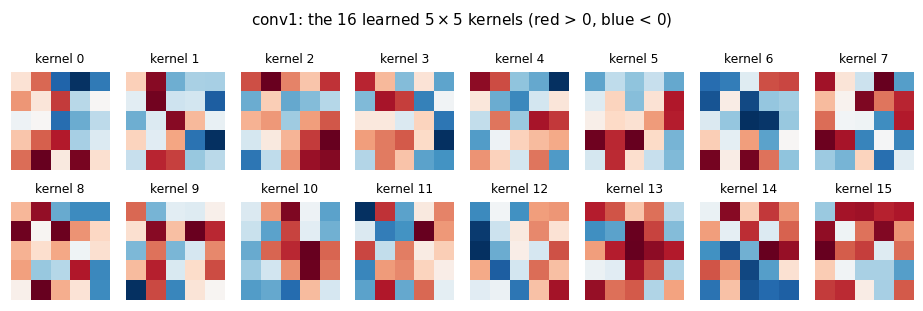

In [9]:
W1 = model.body.conv1.weight.detach().numpy()[:, 0]          # (16, 5, 5): drop the input-channel axis
fig, axs = plt.subplots(2, 8, figsize=(8.5, 3.0))
for k, ax in enumerate(axs.flat):
    v = np.abs(W1[k]).max()
    ax.imshow(W1[k], cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"kernel {k}", fontsize=8); noframe(ax)
fig.suptitle("conv1: the 16 learned $5\\times5$ kernels (red > 0, blue < 0)", fontsize=10)
plt.tight_layout(); plt.show()

### 3.2 Feature maps with forward hooks

A **feature map** is the output of one channel of a convolutional layer: an image showing where in the input the corresponding pattern was found. To see it we need the output of an *intermediate* layer, which `model(x)` does not return.

**Forward hooks.** `layer.register_forward_hook(fn)` attaches a function that PyTorch calls every time `layer` has computed its output, as `fn(module, inputs, output)`. We store the output in a dictionary. The model code stays untouched; the call returns a *handle*, and `handle.remove()` detaches the hook again (hooks left behind keep running and keep memory).

We hook `relu1` and `relu2`, i.e. we record the maps after the activation, which is what the next layer receives:

* after `relu1`: shape `(1, 16, 28, 28)`, 16 maps at full resolution;
* after `relu2`: shape `(1, 32, 14, 14)`, 32 maps at half resolution.

In [10]:
features = {}
def save_output(name):
    def hook(module, inputs, output):
        features[name] = output.detach()
    return hook

handles = [model.body.relu1.register_forward_hook(save_output("relu1")),
           model.body.relu2.register_forward_hook(save_output("relu2"))]

i_img = int(np.flatnonzero(ys_te.numpy() == 3)[0])          # the first test image of a 3
x_one = Xs_te[i_img:i_img + 1]                              # (1, 1, 28, 28): a batch of one image
model.eval()
with torch.inference_mode():
    logits = model(x_one)                                   # the hooks fill `features` during this call
for h in handles:
    h.remove()                                              # detach the hooks

assert features["relu1"].shape == (1, 16, 28, 28) and features["relu2"].shape == (1, 32, 14, 14)
print("predicted digit:", logits.argmax().item(), "| true digit:", ys_te[i_img].item())
for k, v in features.items():
    frac = (v > 0).float().mean().item()
    print(f"{k}: shape {tuple(v.shape)}, fraction of positive (active) entries {frac:.3f}")

predicted digit: 3 | true digit: 3
relu1: shape (1, 16, 28, 28), fraction of positive (active) entries 0.645
relu2: shape (1, 32, 14, 14), fraction of positive (active) entries 0.634


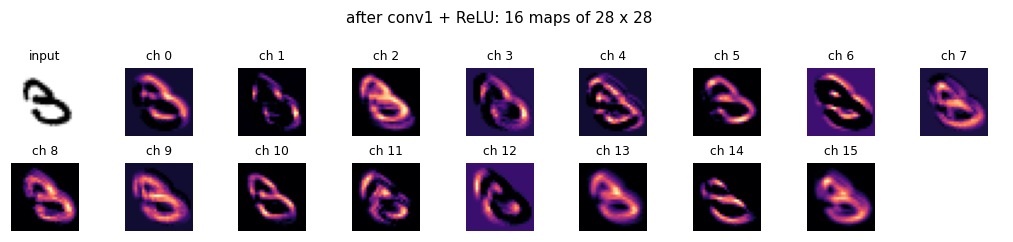

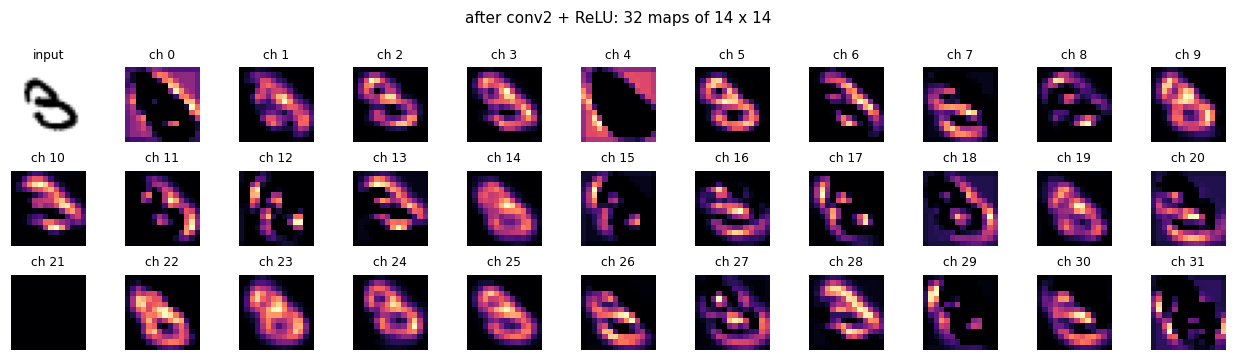

In [11]:
def show_maps(maps, ncols, title, img):
    # maps: (C, H, W); the input image is shown in the first panel
    C = maps.shape[0]
    nrows = int(np.ceil((C + 1) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(1.05 * ncols, 1.1 * nrows))
    axs = axs.flat
    axs[0].imshow(img, cmap="gray_r"); axs[0].set_title("input", fontsize=8)
    for c in range(C):
        axs[c + 1].imshow(maps[c], cmap="magma"); axs[c + 1].set_title(f"ch {c}", fontsize=8)
    for ax in axs: noframe(ax)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

img = x_one[0, 0].numpy()
show_maps(features["relu1"][0].numpy(), 9, "after conv1 + ReLU: 16 maps of 28 x 28", img)
show_maps(features["relu2"][0].numpy(), 11, "after conv2 + ReLU: 32 maps of 14 x 14", img)

**Reading the maps.** Most first-layer maps are filtered copies of the digit. In several of them only one side of the strokes, or only the strokes of one orientation, light up: a kernel with adjacent positive (red) and negative (blue) regions in Section 3.1 responds to a change of brightness in one direction, i.e. it is an oriented edge detector. Other maps respond to the background next to the ink. Second-layer maps have half the resolution, and each channel combines all 16 first-layer maps; the channels respond to more specific configurations, such as strokes of one direction in one part of the digit, and some are sparse for this image. This is the hierarchy of Lecture 4: local, generic patterns (edges, stroke directions) in the first layer, and combinations of them, more specific to the task, deeper in the network.

<hr/>
## 4. Model surgery

All operations of this section create new models from pieces of the trained one. One rule matters throughout: **assigning a module to a new model does not copy it**. `nn.Sequential(model.body, ...)` contains *the same* `body` object; training the new model would also change `model`. Use `copy.deepcopy` whenever the original must stay intact.

### 4.1 Cutting the network: a feature extractor

`model.body` alone maps images to feature vectors of 1568 numbers, `(N, 1, 28, 28) → (N, 1568)`. An `nn.Sequential` can be sliced like a list: `model.body[:6]` stops before the flattening and returns the 32 feature maps, `(N, 32, 7, 7)`; `model.head[:2]` (dense layer + ReLU) applied to the body's output gives the 64 features of the next level, `(N, 64)`.

We compute both kinds of features for 2000 test images of the source digits 0–4 and 2000 of the unseen digits 5–9 and count active units (positive after the ReLU). A unit that is zero for every image ("dead" unit) carries no information about these images. Features that stay active and varied for 5–9 are candidates for re-use in Section 5.

In [12]:
extractor = model.body                                      # (N,1,28,28) -> (N,1568); shares the parameters with `model`
conv_maps = model.body[:6]                                  # conv1 ... pool2: (N,1,28,28) -> (N,32,7,7)
dense_part = model.head[:2]                                 # fc + ReLU:       (N,1568) -> (N,64)
model.eval()
with torch.inference_mode():
    m_src = conv_maps(Xs_te[:2000])                         # (2000, 32, 7, 7)
    feats = {"digits 0-4 (seen)  ": extractor(Xs_te[:2000]),     # (2000, 1568)
             "digits 5-9 (unseen)": extractor(Xt_te[:2000])}
    dense = {k: dense_part(f) for k, f in feats.items()}    # (2000, 64)
assert m_src.shape == (2000, 32, 7, 7) and feats["digits 0-4 (seen)  "].shape == (2000, 1568)
print("feature maps:", tuple(m_src.shape), "| body features:", tuple(feats["digits 0-4 (seen)  "].shape),
      "| dense features:", tuple(dense["digits 0-4 (seen)  "].shape))

def activity(f):
    active = (f > 0).float()
    return active.mean().item(), int((active.sum(0) == 0).sum())

for k in feats:
    a1, d1 = activity(feats[k]); a2, d2 = activity(dense[k])
    print(f"{k}: body features: active fraction {a1:.3f}, never active {d1:4d} of 1568 | "
          f"dense features: active fraction {a2:.3f}, never active {d2:2d} of 64")
f_tgt = feats["digits 5-9 (unseen)"]

feature maps: (2000, 32, 7, 7) | body features: (2000, 1568) | dense features: (2000, 64)
digits 0-4 (seen)  : body features: active fraction 0.762, never active   51 of 1568 | dense features: active fraction 0.531, never active 20 of 64
digits 5-9 (unseen): body features: active fraction 0.767, never active   48 of 1568 | dense features: active fraction 0.566, never active 20 of 64


### 4.2 Trained body, new head

For the digits 5–9 we need a network with the trained body and a *new*, randomly initialised head with 5 outputs. We create a fresh `SmallCNN(n_classes=5)` and copy the body's numbers with `new.body.load_state_dict(model.body.state_dict())`. This copies values: the new body is independent of `model`.

Checks: the new body gives the same feature vectors as the trained one; the new head is random, so the accuracy on the digits 5–9 is near chance level, $1/5=0.2$.

In [13]:
torch.manual_seed(1)
new = SmallCNN(n_classes=5)
new.body.load_state_dict(model.body.state_dict())          # copy the trained body; the head stays random
new.eval()
with torch.inference_mode():
    assert torch.equal(new.body(Xt_te[:2000]), f_tgt)      # identical features
assert new.body.conv1.weight.data_ptr() != model.body.conv1.weight.data_ptr()   # separate memory: no sharing
print("new body gives identical features:", True)
print(f"accuracy on digits 5-9 with the untrained head: {accuracy(new, Xt_te, yt_te):.3f} (chance level 0.2)")

# the pitfall: building a model from the *same* module object shares the parameters
shared = nn.Sequential(model.body, nn.Linear(1568, 5))
print("nn.Sequential(model.body, ...) shares model.body:", shared[0] is model.body,
      "| after copy.deepcopy:", copy.deepcopy(model.body) is model.body)

new body gives identical features: True


accuracy on digits 5-9 with the untrained head: 0.200 (chance level 0.2)
nn.Sequential(model.body, ...) shares model.body: True | after copy.deepcopy: False


### 4.3 Inserting a layer

We insert an extra dense layer, $64\to64$ followed by a ReLU, inside the head, between `relu3` and `out`. If it is initialised as the identity ($W=I$, $b=0$), the network computes exactly the same function as before: its input $h$ is non-negative (it comes out of a ReLU), so $\mathrm{ReLU}(Ih+0)=h$. This is a useful way to enlarge a trained network without losing what it knows; training can then move the new layer away from the identity.

Shapes: body `(N,1568)` → fc, ReLU `(N,64)` → extra, ReLU `(N,64)` → out `(N,5)`. The parameter count grows by $64\cdot64+64=4160$.

In [14]:
extra = nn.Linear(64, 64)
with torch.no_grad():                                       # manual assignment: not recorded by autograd
    extra.weight.copy_(torch.eye(64))
    extra.bias.zero_()

deeper = nn.Sequential(OrderedDict([
    ("body", copy.deepcopy(model.body)),                    # copies: `model` stays untouched
    ("fc", copy.deepcopy(model.head.fc)),
    ("relu3", nn.ReLU()),
    ("extra", extra),                                       # the inserted layer
    ("extra_relu", nn.ReLU()),
    ("out", copy.deepcopy(model.head.out)),
]))
deeper.eval()
with torch.inference_mode():
    same = torch.allclose(deeper(Xs_te), model(Xs_te))
assert same
print("deeper model, logits equal to the original:", same)
print("parameters: original", sum(p.numel() for p in model.parameters()),
      "| deeper", sum(p.numel() for p in deeper.parameters()))

deeper model, logits equal to the original: True
parameters: original 105797 | deeper 109957


### 4.4 Replacing a layer

A layer can be exchanged by assigning a new module to its name, `net.body.pool1 = nn.AvgPool2d(2)`. The replacement must produce an output of the same shape, otherwise the next layer fails. The rest of the network was trained for the *old* layer, so its accuracy changes. Two examples on copies of the trained model:

* max-pooling → average-pooling in `pool1` (same shape `(N,16,14,14)`, different numbers);
* `conv1` → a new, randomly initialised convolution of the same shape: everything after it receives inputs it was never trained on.

In [15]:
net_avg = copy.deepcopy(model)
net_avg.body.pool1 = nn.AvgPool2d(2)                        # replace by name
torch.manual_seed(2)
net_rnd = copy.deepcopy(model)
net_rnd.body.conv1 = nn.Conv2d(1, 16, kernel_size=5, padding=2)   # fresh random kernels, same shapes
print(net_avg.body.pool1, "|", net_rnd.body.conv1)
print(f"test accuracy (digits 0-4): original {accuracy(model, Xs_te, ys_te):.4f} | "
      f"pool1 -> average {accuracy(net_avg, Xs_te, ys_te):.4f} | conv1 re-initialised {accuracy(net_rnd, Xs_te, ys_te):.4f}")

AvgPool2d(kernel_size=2, stride=2, padding=0) | Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))


test accuracy (digits 0-4): original 0.9887 | pool1 -> average 0.9889 | conv1 re-initialised 0.5600


Average pooling changes the numbers passed on but keeps their meaning (the same channels, the same positions), so the accuracy hardly changes. A re-initialised first layer destroys the meaning of all 16 channels for the layers after it, and the accuracy falls far: a trained network is a chain in which each layer is adapted to the layers before it.

<hr/>
## 5. Freezing and transfer learning

### 5.1 The target task with few labels

The new task is to classify the digits 5–9, with only a few labelled images, $n$ per class. **Transfer learning** re-uses the body trained on 0–4: strokes, edges and loops are common to all digits, so the convolutional features of Section 4.1 may also help for 5–9. We compare three strategies with the same number of gradient steps in total (300, minibatches of $\min(64, 5n)$ images, Adam):

| | initial body | trained parameters | steps | learning rate |
|---|---|---|---|---|
| (a) random initialisation | random | all | 300 | $10^{-3}$ |
| (b) frozen body | trained on 0–4 | head only | 200 | $10^{-3}$ |
| (c) fine-tuning | the result of (b) | all | +100 | body $10^{-4}$, head $3\cdot10^{-4}$ |

In (c) the learning rate is smaller: the body is already trained, and large steps driven by a few hundred images would overwrite it (and overfit). The labelled subset is drawn with a NumPy generator (`seed`), class by class, so Lab 003b uses exactly the same images. Below we first run the three strategies in detail for $n=100$ images per class (500 labelled images), and in Section 5.5 for several $n$.

In [16]:
def labelled_subset(n_per_class, seed):
    # n_per_class images of each target class, drawn from the pool without replacement
    rng = np.random.default_rng(seed)
    y = yt_pool.numpy()
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), n_per_class, replace=False) for c in range(5)])
    return Xt_pool[idx], yt_pool[idx]

def train_steps(model, opt, X, y, steps, seed):
    # `steps` Adam steps on minibatches of min(64, len(X)) images drawn at random
    rng = np.random.default_rng(seed)
    bs = min(64, len(X))
    model.train()
    for _ in range(steps):
        idx = torch.from_numpy(rng.choice(len(X), bs, replace=False))
        loss = F.cross_entropy(model(X[idx]), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

def transfer_model(seed):
    # trained body (copied), new random head with 5 outputs
    torch.manual_seed(seed)
    m = SmallCNN(5)
    m.body.load_state_dict(model.body.state_dict())
    return m

X_lab, y_lab = labelled_subset(100, seed=0)
assert X_lab.shape == (500, 1, 28, 28) and torch.equal(torch.bincount(y_lab), torch.full((5,), 100))
print("labelled set:", tuple(X_lab.shape), "| images per class:", torch.bincount(y_lab).tolist())

labelled set: (500, 1, 28, 28) | images per class: [100, 100, 100, 100, 100]


### 5.2 (a) Random initialisation

All 105 797 parameters start random and are trained on the 500 labelled images only.

In [17]:
torch.manual_seed(10)
net_a = SmallCNN(5)
opt = torch.optim.Adam(net_a.parameters(), lr=1e-3)
last = train_steps(net_a, opt, X_lab, y_lab, steps=300, seed=0)
acc_a = accuracy(net_a, Xt_te, yt_te)
print(f"(a) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_a:.4f}")

(a) last minibatch loss 0.0121 | test accuracy on digits 5-9: 0.9317


### 5.3 (b) Frozen body, new head

**The mechanism in PyTorch** has two parts:

1. `p.requires_grad_(False)` for every parameter of the body: `backward()` no longer computes their gradients (`p.grad` stays `None`), which also saves computation;
2. the optimiser receives only the head's parameters, `torch.optim.Adam(net.head.parameters())`, so it cannot change anything else.

Either part alone would already keep the body fixed for plain Adam; using both is the safe habit. (One caution for other networks: batch normalisation layers update their running statistics in `train()` mode even when their parameters are frozen; a frozen body containing them is put in `eval()` mode.)

**Check.** We copy the body's parameters before training and assert afterwards that they are bit-for-bit unchanged, while the head did change.

In [18]:
net_b = transfer_model(seed=10)
for p in net_b.body.parameters():
    p.requires_grad_(False)                                   # freeze the body
tr, fr = count_params(net_b)
print(f"trainable parameters: {tr} (head) | frozen parameters: {fr} (body)")
assert tr == (1568 * 64 + 64) + (64 * 5 + 5)

body_before = copy.deepcopy(net_b.body.state_dict())          # snapshot for the check
head_before = copy.deepcopy(net_b.head.state_dict())
opt = torch.optim.Adam(net_b.head.parameters(), lr=1e-3)      # the optimiser sees only the head
last = train_steps(net_b, opt, X_lab, y_lab, steps=200, seed=0)

body_after, head_after = net_b.body.state_dict(), net_b.head.state_dict()
assert all(torch.equal(body_before[k], body_after[k]) for k in body_before), "frozen body changed!"
assert not torch.equal(head_before["fc.weight"], head_after["fc.weight"])
print("body parameters unchanged:", True, "| head changed:", True, "| body.conv1.weight.grad:", net_b.body.conv1.weight.grad)
acc_b = accuracy(net_b, Xt_te, yt_te)
print(f"(b) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_b:.4f}")

trainable parameters: 100741 (head) | frozen parameters: 5056 (body)


body parameters unchanged: True | head changed: True | body.conv1.weight.grad: None


(b) last minibatch loss 0.0520 | test accuracy on digits 5-9: 0.9461


**The place of the cut matters.** Section 3 suggested that early layers compute generic patterns and later layers task-specific ones. A direct test: cut one layer later, i.e. keep the trained dense layer `head.fc` frozen as well and train only a new output layer (325 parameters) on the same 500 images, with the same 200 steps.

In [19]:
net_b2 = copy.deepcopy(model)                                  # trained body and trained dense layer
torch.manual_seed(10)
net_b2.head.out = nn.Linear(64, 5)                             # new output layer
for name, p in net_b2.named_parameters():
    p.requires_grad_(name.startswith("head.out"))              # freeze everything except the output layer
print("trainable / frozen parameters:", count_params(net_b2))
train_steps(net_b2, torch.optim.Adam(net_b2.head.out.parameters(), lr=1e-3), X_lab, y_lab, steps=200, seed=0)
acc_b2 = accuracy(net_b2, Xt_te, yt_te)
print(f"test accuracy on digits 5-9: cut after the convolutional body {acc_b:.4f} | cut after the dense layer {acc_b2:.4f}")

trainable / frozen parameters: (325, 105472)


test accuracy on digits 5-9: cut after the convolutional body 0.9461 | cut after the dense layer 0.6589


### 5.4 (c) Fine-tuning everything with a smaller learning rate

We continue from the result of (b): unfreeze the body (`requires_grad_(True)`) and train all parameters for 100 more steps. **Parameter groups** give different parts of the network different hyperparameters within one optimiser: a list of dictionaries, each with its own `"params"` and `"lr"`. Here the body moves with $10^{-4}$ and the head with $3\cdot10^{-4}$.

In [20]:
net_c = copy.deepcopy(net_b)                                   # (b) stays available
for p in net_c.body.parameters():
    p.requires_grad_(True)                                     # unfreeze
print("trainable / frozen parameters:", count_params(net_c))

opt = torch.optim.Adam([
    {"params": net_c.body.parameters(), "lr": 1e-4},           # group 0: body, small steps
    {"params": net_c.head.parameters(), "lr": 3e-4},           # group 1: head
])
print("learning rates of the parameter groups:", [g["lr"] for g in opt.param_groups])
last = train_steps(net_c, opt, X_lab, y_lab, steps=100, seed=1)
assert not torch.equal(net_c.body.conv1.weight, net_b.body.conv1.weight)   # the body did move this time
acc_c = accuracy(net_c, Xt_te, yt_te)
print(f"(c) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_c:.4f}")
print(f"\nn = 100 images per class: (a) {acc_a:.4f} | (b) {acc_b:.4f} | (c) {acc_c:.4f}")

trainable / frozen parameters: (105797, 0)
learning rates of the parameter groups: [0.0001, 0.0003]


(c) last minibatch loss 0.0074 | test accuracy on digits 5-9: 0.9475

n = 100 images per class: (a) 0.9317 | (b) 0.9461 | (c) 0.9475


### 5.5 Accuracy vs number of labelled images

We repeat (a), (b), (c) for $n\in\{10, 30, 100, 300\}$ images per class, i.e. 50 to 1500 labelled images, each with 3 different labelled subsets (seeds 0, 1, 2). The figure shows the mean test accuracy on all 4861 test images of the digits 5–9; the error bars are the standard deviation over the 3 subsets.

In [21]:
def run_all(n_per_class, seed):
    X, y = labelled_subset(n_per_class, seed)
    torch.manual_seed(100 + seed)                               # (a) random initialisation
    m = SmallCNN(5)
    train_steps(m, torch.optim.Adam(m.parameters(), lr=1e-3), X, y, 300, seed)
    acc = [accuracy(m, Xt_te, yt_te)]
    m = transfer_model(100 + seed)                              # (b) frozen body
    for p in m.body.parameters(): p.requires_grad_(False)
    train_steps(m, torch.optim.Adam(m.head.parameters(), lr=1e-3), X, y, 200, seed)
    acc.append(accuracy(m, Xt_te, yt_te))
    for p in m.body.parameters(): p.requires_grad_(True)       # (c) fine-tuning, continues from (b)
    opt = torch.optim.Adam([{"params": m.body.parameters(), "lr": 1e-4}, {"params": m.head.parameters(), "lr": 3e-4}])
    train_steps(m, opt, X, y, 100, seed + 1000)
    acc.append(accuracy(m, Xt_te, yt_te))
    return acc

t0 = time.time()
N_PER_CLASS = [10, 30, 100, 300]
SEEDS = [0, 1, 2]
acc = np.array([[run_all(n, s) for s in SEEDS] for n in N_PER_CLASS])   # (n values, seeds, strategies)
print(f"sweep time: {time.time() - t0:.0f} s\n")
print("test accuracy on digits 5-9, mean ± std over 3 labelled subsets")
print(f"{'n per class':>12s} {'(a) random init':>18s} {'(b) frozen body':>18s} {'(c) fine-tuned':>18s}")
for i, n in enumerate(N_PER_CLASS):
    print(f"{n:12d} " + " ".join(f"{acc[i, :, j].mean():11.4f} ± {acc[i, :, j].std():.4f}" for j in range(3)))

sweep time: 127 s

test accuracy on digits 5-9, mean ± std over 3 labelled subsets
 n per class    (a) random init    (b) frozen body     (c) fine-tuned
          10      0.8542 ± 0.0146      0.8709 ± 0.0213      0.8686 ± 0.0213
          30      0.9085 ± 0.0116      0.9226 ± 0.0062      0.9223 ± 0.0065
         100      0.9423 ± 0.0007      0.9504 ± 0.0017      0.9526 ± 0.0026
         300      0.9717 ± 0.0022      0.9625 ± 0.0047      0.9689 ± 0.0016


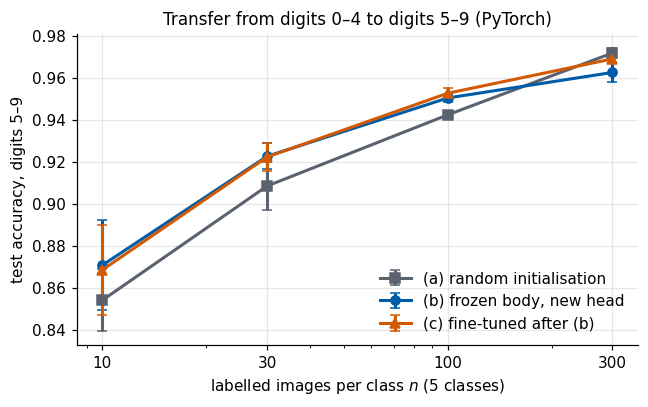

In [22]:
labels = ["(a) random initialisation", "(b) frozen body, new head", "(c) fine-tuned after (b)"]
colors, markers = [UJGray, UJBlue, DSOrange], ["s", "o", "^"]
fig, ax = plt.subplots(figsize=(6, 3.8))
for j in range(3):
    m, s = acc[:, :, j].mean(1), acc[:, :, j].std(1)
    ax.errorbar(N_PER_CLASS, m, yerr=s, color=colors[j], marker=markers[j], ms=6, lw=2, capsize=3, label=labels[j])
ax.set_xscale("log"); ax.set_xticks(N_PER_CLASS); ax.set_xticklabels(N_PER_CLASS)
ax.set_xlabel("labelled images per class $n$ (5 classes)")
ax.set_ylabel("test accuracy, digits 5–9")
ax.set_title("Transfer from digits 0–4 to digits 5–9 (PyTorch)")
ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Reading the figure.** For $n=30$ and $n=100$ images per class the trained body helps: (b) and (c) lie above (a) by more than the spread over the labelled subsets. For $n=10$ the mean is also higher, but the spread over subsets is of the same size as the difference. At $n=300$ the network trained from a random initialisation catches up: with enough labels it learns features for 5–9 by itself, while the frozen body keeps the features learned for 0–4. Fine-tuning (c) gives at most a small gain over (b) with these 100 extra steps.

The gains from transfer are modest here because the target task is easy: a small CNN trained from a random initialisation on 50 images already classifies most test digits correctly. The choice of the cut (Section 5.3) mattered much more: a frozen dense layer trained on 0–4 left far fewer correctly classified digits than the frozen convolutional body. Generic early features transfer; task-specific late features do not.

<hr/>
## 6. Cheat sheet: PyTorch and JAX/Flax NNX

| operation | PyTorch | JAX / Flax NNX |
|---|---|---|
| image layout | `(N, C, H, W)` | `(N, H, W, C)` |
| conv kernel shape | `(out, in, kh, kw)` | `(kh, kw, in, out)` |
| dense weight shape | `weight: (out, in)`, $y=xW^T+b$ | `kernel: (in, out)`, $y=xK+b$ |
| save | `torch.save(model.state_dict(), "f.pt")` | `flat = flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")`; `np.savez("f.npz", **flat)` |
| load into fresh model | `fresh.load_state_dict(torch.load("f.pt", weights_only=True))` | `st = nnx.state(fresh, nnx.Param)`; `nnx.replace_by_pure_dict(st, unflatten_dict(dict(np.load("f.npz")), sep="/"))`; `nnx.update(fresh, st)` |
| list parameters | `for name, p in model.named_parameters()` | `flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")` |
| one layer's weights | `model.body.conv1.weight.detach().numpy()` | `np.asarray(model.body.conv1.kernel[...])` |
| set weights by hand | `with torch.no_grad(): layer.weight.copy_(W)` | `layer.kernel[...] = W` |
| intermediate outputs | `layer.register_forward_hook(fn)`, `handle.remove()` | call submodules step by step, or `nnx.capture(model, nnx.Intermediate, method_outputs=nnx.Intermediate)(x)` |
| feature extractor | `model.body`, or slice `model.body[:6]` | `model.body`; a partial forward pass is written as a function |
| new head on trained body | `new.body.load_state_dict(model.body.state_dict())` | `nnx.update(new.body, nnx.state(model.body))` |
| copy a module | `copy.deepcopy(m)` | `nnx.clone(m)` |
| insert a layer | `nn.Sequential(body, extra, nn.ReLU(), head)` | `nnx.Sequential(body, extra, nnx.relu, head)` |
| replace a layer | `net.body.pool1 = nn.AvgPool2d(2)` | `net.body.pool1 = partial(nnx.avg_pool, window_shape=(2, 2), strides=(2, 2))` |
| freeze | `p.requires_grad_(False)`; optimiser gets `net.head.parameters()` | `nnx.Optimizer(net, tx, wrt=head_filter)` and `nnx.grad(..., argnums=nnx.DiffState(0, head_filter))`, or `optax.multi_transform` with `optax.set_to_zero()` for the body |
| where "frozen" lives | in the parameter (`requires_grad`) | in the optimiser and the gradient call (the model has no such flag) |
| per-part learning rates | parameter groups `[{"params": ..., "lr": ...}, ...]` | `optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(3e-4)}, labels)` |

In [23]:
print(f"total run time of the notebook: {time.time() - t_start:.0f} s")

total run time of the notebook: 167 s
